In [39]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
import sqlite3 

directorio_datos = Path('SINEX')
directorio_bd = Path("datos")
archivo_bd = directorio_bd / "sinex.db"

In [40]:
def EsEntero(num):
    try:
        k = int(num)
        return k
    except:
        return -1

In [41]:
def PintarMenu(listaOpc):
    """
    Muestra un menú y comprueba que la opción elegida es correcta
    Recibe listaOpc, que es una lista con las opciones que muestra
    Devuelve k, la opción elegida por el usuario
    """
    seguir = True
    while(seguir):
        for i,opcion in enumerate(listaOpc):
            print(f"{i}.-{opcion}")
        cad = input("Inserte una opción: ")
        k = EsEntero(cad)
        if 0<=k and k< len(listaOpc):
            return k 
        elif k == -1:
            print("\nDebe insertar un número entero.\n")
        else:
            print(f"\nEl número debe estar entre 0 y {len(listaOpc)-1}.\n")

In [42]:
def ComprobarCarpeta():
    if not os.path.exists("./datos"):
        os.makedirs("./datos")

In [43]:
def CrearBase():

    '''CrearBase crea la base de datos y las tablas necesarias para almacenar los datos de los archivos SINEX.'''

    ComprobarCarpeta()
    
    with sqlite3.connect(archivo_bd) as con:
        con.execute('''CREATE TABLE IF NOT EXISTS Estimaciones (
            FECHA TEXT NOT NULL,
            NOMBRE_ESTACION TEXT NOT NULL,
            X REAL NOT NULL,
            DTX REAL NOT NULL,
            Y REAL NOT NULL,
            DTY REAL NOT NULL,
            Z REAL NOT NULL,
            DTZ REAL NOT NULL,
            PRIMARY KEY (FECHA, NOMBRE_ESTACION))''')
        con.execute('''CREATE TABLE IF NOT EXISTS CoordenadasTopocentricas (
            FECHA REAL NOT NULL,
            NOMBRE_ESTACION TEXT NOT NULL,
            ESTE REAL NOT NULL,
            NORTE REAL NOT NULL,
            ELEVACION REAL NOT NULL,
            SIGMA_E REAL,
            SIGMA_N REAL,
            SIGMA_U REAL,
            PRIMARY KEY (FECHA, NOMBRE_ESTACION))''')
        con.execute('''CREATE TABLE IF NOT EXISTS Velocidades (
            NOMBRE_ESTACION TEXT PRIMARY KEY,
            LATITUD REAL,
            LONGITUD REAL,
            VELOCIDAD_ESTE REAL,
            VELOCIDAD_NORTE REAL,
            VELOCIDAD_ALTURA REAL)''')
        
    print(f"Base de datos preparada: {archivo_bd}")

In [44]:
def ExisteBase():
    if os.path.exists("./datos/sinex.db"):
        return(True)
    else:
        return(False)

In [45]:
def ExisteTabla(cursor, nombre_tabla):
    cursor.execute(f"SELECT name FROM sqlite_master WHERE type='table' AND name='{nombre_tabla}'")
    return cursor.fetchone() is not None

In [46]:
# Bloque I: Lectura de archivos SINEX y extracción de datos

def LeerArchivosSINEX():

    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return

    archivos = list(directorio_datos.glob('*.SNX'))
    tabla_datos = []

    for archivo in archivos:
        with open(archivo, 'r', encoding='latin-1') as fidin:
            lines = fidin.readlines()
            
        i = 0
        n_lines = len(lines)
        while i < n_lines:
            linea = lines[i]
            if len(linea) >= 18 and linea[0:18] == "+SOLUTION/ESTIMATE":
                i += 1
                if i < n_lines:
                    linea = lines[i]
                if i < n_lines:
                    i += 1
                    linea = lines[i]
                    
                fecha_str = linea[27:39].strip() if len(linea) >= 39 else ""
                
                while i < n_lines and lines[i][0:18] != "-SOLUTION/ESTIMATE":
                    line_x = lines[i]
                    if len(line_x) < 80:
                        i += 1
                        continue
                    
                    nombre_est = line_x[14:18].strip()
                    x = float(line_x[46:68])
                    dtx = float(line_x[69:80])
                    
                    i += 1
                    line_y = lines[i]
                    y = float(line_y[46:68])
                    dty = float(line_y[69:80])
                    
                    i += 1
                    line_z = lines[i]
                    z = float(line_z[46:68])
                    dtz = float(line_z[69:80])
                    
                    tabla_datos.append([fecha_str, nombre_est, x, dtx, y, dty, z, dtz])
                    i += 1
            i += 1

    TABLA = pd.DataFrame(tabla_datos, columns=['FECHA', 'NOMBRE_ESTACION', 'X', 'DTX', 'Y', 'DTY', 'Z', 'DTZ'])

    if TABLA.empty:
        print("No se han encontrado estimaciones válidas.")
        return

    TABLA = TABLA.drop_duplicates(subset=['FECHA', 'NOMBRE_ESTACION'], keep='last')

    with sqlite3.connect(archivo_bd) as con:
        con.executemany("""
            INSERT OR REPLACE INTO Estimaciones
            (FECHA, NOMBRE_ESTACION, X, DTX, Y, DTY, Z, DTZ)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?)
        """, TABLA.values.tolist())

    print(f"Registros guardados en SQLite: {len(TABLA)}")

    return TABLA

In [47]:
def ObtenerEstacion(nombre_estacion):
    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return pd.DataFrame()
    
    with sqlite3.connect(archivo_bd) as con:
        if not ExisteTabla(con.cursor(), 'Estimaciones'):
            print("La tabla Estimaciones no existe. Abortando...")
            return pd.DataFrame()
        
        df = pd.read_sql_query('''SELECT * FROM Estimaciones
            WHERE NOMBRE_ESTACION = ? ORDER BY FECHA''', con, params=(nombre_estacion.upper(),))
        
    if df.empty:
        print(f"No hay estimaciones para la estación {nombre_estacion.upper()}.")
    return df

In [48]:
# Bloque II: Conversión de fechas y cálculo de coordenadas topocéntricas

def sinex2anno_decimal(fecha_str):
    partes = str(fecha_str).split(':')
    yy = 2000 + int(partes[0])
    ddd = float(partes[1])
    sssss = float(partes[2])
    
    segundos_por_dia = 86400.0
    fraccion_dia = sssss / segundos_por_dia
    
    es_bisiesto = (yy % 4 == 0 and yy % 100 != 0) or (yy % 400 == 0)
    dias_en_anno = 366.0 if es_bisiesto else 365.0
    
    return yy + (ddd - 1.0 + fraccion_dia) / dias_en_anno

def metodoferrari(X, Y, Z):
    
    a = 6378137.0
    f = 1 / 298.257222101
    e2 = 2*f - f**2

    lambda_geo = np.arctan2(Y, X)
    r = np.sqrt(X**2 + Y**2)
    E2 = a**2 - (a * (1 - f))**2
    F = 54 * (a * (1 - f))**2 * Z**2
    G = r**2 + (1 - e2)*Z**2 - e2*E2
    c = (e2**2 * F * r**2) / (G**3)
    radicando = max(0.0, c**2 + 2*c)
    s = (1 + c + np.sqrt(radicando))**(1/3)
    P = F / (3 * (s + 1/s + 1)**2 * G**2)
    Q = np.sqrt(1 + 2 * e2**2 * P)
    r0 = -(P * e2 * r) / (1 + Q) + np.sqrt(0.5 * a**2 * (1 + 1/Q) - P * (1 - e2) * Z**2 / (Q * (1 + Q)) - 0.5 * P * r**2)
    U = np.sqrt((r - e2 * r0)**2 + Z**2)
    V = np.sqrt((r - e2 * r0)**2 + (1 - e2) * Z**2)
    b = a * (1 - f)
    e2p = (a**2 - b**2) / b**2
    z0 = (b**2 * Z) / (a * V)
    h = U * (1 - b**2 / (a * V))
    phi = np.arctan((Z + e2p * z0) / r)
    
    return phi, lambda_geo, h

def CalcularCoordenadasTopocentricas():
    
    '''CalcularCoordenadasTopocentricas calcula las coordenadas topocéntricas a partir de las estimaciones.'''
    
    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return
    
    with sqlite3.connect(archivo_bd) as con:
        df = pd.read_sql_query('SELECT * FROM Estimaciones ORDER BY NOMBRE_ESTACION, FECHA', con)

    if df.empty:
        print("No hay estimaciones guardadas. Importa primero los archivos SINEX.")
        return
    
    df['ANNO_DECIMAL'] = df['FECHA'].apply(sinex2anno_decimal)
    resultados = []

    for estacion, df_est in df.groupby('NOMBRE_ESTACION'):
        df_est = df_est.sort_values('ANNO_DECIMAL').reset_index(drop=True)
        X, Y, Z = df_est['X'].to_numpy(), df_est['Y'].to_numpy(), df_est['Z'].to_numpy()
        DX, DY, DZ = df_est['DTX'].to_numpy(), df_est['DTY'].to_numpy(), df_est['DTZ'].to_numpy()
        X0, Y0, Z0 = X[0], Y[0], Z[0]
        phi, lam, _ = metodoferrari(X0, Y0, Z0)
        R = np.array([[-np.sin(lam), np.cos(lam), 0], [-np.sin(phi)*np.cos(lam), -np.sin(phi)*np.sin(lam), np.cos(phi)], [np.cos(phi)*np.cos(lam), np.cos(phi)*np.sin(lam), np.sin(phi)]])
        for j in range(len(df_est)):
            delta = np.array([X[j] - X0, Y[j] - Y0, Z[j] - Z0])
            topo = R @ delta
            sigma_xyz = np.diag([DX[j]**2, DY[j]**2, DZ[j]**2])
            sigma_enu = R @ sigma_xyz @ R.T
            desviaciones = np.sqrt(np.diag(sigma_enu))
            resultados.append([df_est.loc[j, 'ANNO_DECIMAL'], estacion, topo[0], topo[1], topo[2], desviaciones[0], desviaciones[1], desviaciones[2]])

    tabla = pd.DataFrame(resultados, columns=['FECHA', 'NOMBRE_ESTACION', 'ESTE', 'NORTE', 'ELEVACION', 'SIGMA_E', 'SIGMA_N', 'SIGMA_U'])

    with sqlite3.connect(archivo_bd) as con:
        con.execute('DELETE FROM CoordenadasTopocentricas')
        con.executemany('''INSERT OR REPLACE INTO CoordenadasTopocentricas
            (FECHA, NOMBRE_ESTACION, ESTE, NORTE, ELEVACION, SIGMA_E, SIGMA_N, SIGMA_U)
            VALUES (?, ?, ?, ?, ?, ?, ?, ?)''', tabla.values.tolist())
        
    print(f"Coordenadas topocéntricas calculadas: {len(tabla)} registros.")
    return tabla


In [49]:
def ObtenerCoordenadasTopocentricas(nombre_estacion=None):
    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return pd.DataFrame()
    
    consulta = 'SELECT * FROM CoordenadasTopocentricas'
    parametros = ()

    if nombre_estacion:
        consulta += ' WHERE NOMBRE_ESTACION = ?'
        parametros = (nombre_estacion.upper(),)
    consulta += ' ORDER BY NOMBRE_ESTACION, FECHA'
    
    with sqlite3.connect(archivo_bd) as con:
        return pd.read_sql_query(consulta, con, params=parametros)

In [50]:
def ExportarCoordenadasTopocentricas():

    with sqlite3.connect(archivo_bd) as con:
        tabla = pd.read_sql_query("""
            SELECT *
            FROM CoordenadasTopocentricas
            ORDER BY NOMBRE_ESTACION, FECHA
        """, con)

    if tabla.empty:
        print("No hay coordenadas topocéntricas para exportar.")
        return

    filename_topo = Path("estaciones_topocentricas.xlsx")

    with pd.ExcelWriter(filename_topo, engine="openpyxl") as writer:
        for estacion, df_est in tabla.groupby("NOMBRE_ESTACION"):
            df_est.drop(columns=["NOMBRE_ESTACION"]).to_excel(
                writer,
                sheet_name=estacion[:31],
                index=False
            )

    print(f"Coordenadas topocéntricas exportadas correctamente a {filename_topo}.")


In [51]:
# Bloque III: Graficación de coordenadas ECEF

def graficar_ecef(estacion, titulo):
    df_est = ObtenerEstacion(estacion)
    if df_est.empty:
        print(f"No hay datos para la estación: {estacion}")
        return
        
    df_est = df_est.copy()
    df_est['FECHA'] = df_est['FECHA'].apply(sinex2anno_decimal)
    
    # 1. Filtrado de outliers mediante IQR (Rango Intercuartílico)
    for col in ['X', 'Y', 'Z']:
        q25, q75 = df_est[col].quantile(0.25), df_est[col].quantile(0.75)
        iqr = q75 - q25
        df_est = df_est[(df_est[col] >= q25 - 3 * iqr) & (df_est[col] <= q75 + 3 * iqr)]
    
    # 2. Conversión a desviaciones en milímetros respecto a la mediana
    for col in ['X', 'Y', 'Z']:
        df_est[f'd{col}_mm'] = (df_est[col] - df_est[col].median()) * 1000.0
        if f'DT{col}' in df_est.columns:
            df_est[f'DT{col}_mm'] = df_est[f'DT{col}'] * 1000.0

    # 3. Creación de la figura y subplots
    fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    
    config = [
        ('X', 'dX_mm', 'DTX_mm', '$\Delta X$ (mm)', 'tab:blue'),
        ('Y', 'dY_mm', 'DTY_mm', '$\Delta Y$ (mm)', 'tab:orange'),
        ('Z', 'dZ_mm', 'DTZ_mm', '$\Delta Z$ (mm)', 'tab:green')
    ]
    
    for ax, (col_orig, col_delta, col_err, etiqueta, color) in zip(axs, config):
        x_data = df_est['FECHA']
        y_data = df_est[col_delta]
        
        # Puntos individuales con/sin barras de incertidumbre
        if col_err in df_est.columns:
            ax.errorbar(x_data, y_data, yerr=df_est[col_err], fmt='o', ms=2, 
                        color=color, ecolor='gray', elinewidth=0.4, alpha=0.6, label='Estimación SINEX')
        else:
            ax.plot(x_data, y_data, 'o', ms=2, color=color, alpha=0.6, label='Estimación SINEX')
        
        # Ajuste lineal para obtener la tendencia (velocidad en mm/año)
        if len(df_est) > 1:
            p = np.polyfit(x_data, y_data, 1)
            velocidad = p[0]  # Pendiente mm/año
            ax.plot(x_data, np.polyval(p, x_data), color='black', linestyle='--', 
                    linewidth=1.2, label=f'Tendencia: {velocidad:+.2f} mm/año')
        
        ax.set_ylabel(etiqueta, fontsize=10)
        ax.set_title(f'Componente {col_orig}', fontsize=10, loc='left', fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.7)
        ax.legend(loc='upper right', frameon=True, fontsize=8)

    axs[2].set_xlabel('Año decimal', fontsize=11)
    fig.suptitle(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [52]:
# Bloque IV: Graficación de coordenadas topocéntricas

def graficar_topocentricas(estacion, titulo):
    df = ObtenerCoordenadasTopocentricas(estacion)
    if df.empty:
        print("No hay coordenadas topocéntricas. Calcula primero las coordenadas.")
        return
        
    df = df.copy()
    
    # Asegurar conversión de fecha a año decimal si viniera como texto/objeto
    if df['FECHA'].dtype == object or isinstance(df['FECHA'].iloc[0], str):
        df['FECHA'] = df['FECHA'].apply(sinex2anno_decimal)
    
    # 1. Filtrado de outliers mediante IQR (Rango Intercuartílico)
    for col in ['ESTE', 'NORTE', 'ELEVACION']:
        if col in df.columns:
            q25, q75 = df[col].quantile(0.25), df[col].quantile(0.75)
            iqr = q75 - q25
            df = df[(df[col] >= q25 - 3 * iqr) & (df[col] <= q75 + 3 * iqr)]
    
    # 2. Conversión a desviaciones en milímetros (mm) respecto a la mediana
    for col in ['ESTE', 'NORTE', 'ELEVACION']:
        if col in df.columns:
            df[f'd{col}_mm'] = (df[col] - df[col].median()) * 1000.0
            # Si existen columnas de error (ej. DTESTE, DTNORTE, DTELEVACION)
            if f'DT{col}' in df.columns:
                df[f'DT{col}_mm'] = df[f'DT{col}'] * 1000.0

    # 3. Creación de la figura y subplots
    fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    
    config = [
        ('ESTE', 'dESTE_mm', 'DTESTE_mm', '$\Delta$ Este (mm)', 'tab:blue'),
        ('NORTE', 'dNORTE_mm', 'DTNORTE_mm', '$\Delta$ Norte (mm)', 'tab:orange'),
        ('ELEVACION', 'dELEVACION_mm', 'DTELEVACION_mm', '$\Delta$ Elevación (mm)', 'tab:green')
    ]
    
    for ax, (col_orig, col_delta, col_err, etiqueta, color) in zip(axs, config):
        x_data = df['FECHA']
        y_data = df[col_delta]
        
        # Puntos disjuntos con barras de incertidumbre si están disponibles
        if col_err in df.columns:
            ax.errorbar(x_data, y_data, yerr=df[col_err], fmt='o', ms=2, 
                        color=color, ecolor='gray', elinewidth=0.4, alpha=0.6, label='Topocéntricas')
        else:
            ax.plot(x_data, y_data, 'o', ms=2, color=color, alpha=0.6, label='Topocéntricas')
        
        # Ajuste lineal para obtener la velocidad en mm/año
        if len(df) > 1:
            p = np.polyfit(x_data, y_data, 1)
            velocidad = p[0]  # Pendiente mm/año
            ax.plot(x_data, np.polyval(p, x_data), color='black', linestyle='--', 
                    linewidth=1.2, label=f'Velocidad: {velocidad:+.2f} mm/año')
        
        ax.set_ylabel(etiqueta, fontsize=10)
        ax.set_title(f'Componente {col_orig.capitalize()}', fontsize=10, loc='left', fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.7)
        ax.legend(loc='upper right', frameon=True, fontsize=8)

    axs[2].set_xlabel('Año decimal', fontsize=11)
    fig.suptitle(titulo, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [53]:
# Bloque V: Suavizado de series temporales mediante Wavelet

def wden_equivalent(data, wavelet='coif5'):
    data = np.asarray(data)
    w = pywt.Wavelet(wavelet)
    max_lev = pywt.dwt_max_level(len(data), w.dec_len)
    if max_lev == 0:
        return data.copy()
    coeffs = pywt.wavedec(data, wavelet, level=max_lev)
    d1 = coeffs[-1]
    sigma = np.median(np.abs(d1)) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(len(data)))
    new_coeffs = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
    return pywt.waverec(new_coeffs, wavelet)[:len(data)]


def procesar_y_graficar_wavelet(estacion, nombre_estacion):
    df = ObtenerCoordenadasTopocentricas(estacion)
    if df.empty:
        print("No hay coordenadas topocéntricas. Calcula primero las coordenadas.")
        return

    df = df.copy()

    # Convertir fecha a año decimal si viniera como texto
    if df['FECHA'].dtype == object or isinstance(df['FECHA'].iloc[0], str):
        df['FECHA'] = df['FECHA'].apply(sinex2anno_decimal)

    componentes = [
        ('ESTE', 'Este', 'tab:blue'),
        ('NORTE', 'Norte', 'tab:orange'),
        ('ELEVACION', 'Elevación', 'tab:green')
    ]

    for col, comp_title, color in componentes:
        # 1. Convertir a milímetros respecto a la mediana
        s_mm = (df[col] - df[col].median()) * 1000.0

        # 2. Reemplazar Outliers por NaN usando Rango Intercuartílico (IQR)
        q25, q75 = s_mm.quantile(0.25), s_mm.quantile(0.75)
        iqr = q75 - q25
        s_mm_clean = s_mm.mask((s_mm < q25 - 3 * iqr) | (s_mm > q75 + 3 * iqr))

        # 3. Interpolar huecos (las wavelets no aceptan NaNs ni datos faltantes)
        signal_interp = s_mm_clean.interpolate(method='linear').bfill().ffill().to_numpy()

        # 4. Aplicar filtrado Wavelet sobre la señal limpia
        denoised = wden_equivalent(signal_interp, wavelet='coif5')

        # 5. Representación gráfica
        plt.figure(figsize=(10, 3.8))

        # Datos medidos (Puntos aislados)
        plt.plot(df['FECHA'], s_mm_clean, 'o', ms=2.5, color=color, alpha=0.4, label='Serie Filtrada (sin outliers)')

        # Señal reconstruida por Wavelet (Línea continua)
        plt.plot(df['FECHA'], denoised, color='black', linewidth=1.5, label='Filtro Wavelet (coif5)')

        plt.title(f'Análisis Wavelet — Componente {comp_title} (Estación {nombre_estacion})', fontweight='bold')
        plt.xlabel('Año decimal')
        plt.ylabel(f'$\Delta$ {comp_title} (mm)')
        plt.legend(loc='upper right', frameon=True)
        plt.grid(True, linestyle=':', alpha=0.7)
        plt.tight_layout()
        plt.show()

In [54]:
# Bloque VI: Cálculo de velocidades topocéntricas

def CalcularVelocidadesTopocentricas():
    tabla = ObtenerCoordenadasTopocentricas()

    if tabla.empty:
        print("No hay coordenadas topocéntricas. Calcula primero las coordenadas.")
        return
    
    with sqlite3.connect(archivo_bd) as con:
        estimaciones = pd.read_sql_query('SELECT * FROM Estimaciones ORDER BY NOMBRE_ESTACION, FECHA', con)

    resultados = []
    for estacion, df_est in tabla.groupby('NOMBRE_ESTACION'):
        df_est = df_est.sort_values('FECHA')

        if len(df_est) < 2:
            continue

        t = df_est['FECHA'].to_numpy()
        v_este = 1000 * np.polyfit(t, df_est['ESTE'].to_numpy(), 1)[0]
        v_norte = 1000 * np.polyfit(t, df_est['NORTE'].to_numpy(), 1)[0]
        v_altura = 1000 * np.polyfit(t, df_est['ELEVACION'].to_numpy(), 1)[0]
        df_xyz = estimaciones[estimaciones['NOMBRE_ESTACION'] == estacion]

        if df_xyz.empty:
            continue

        fila = df_xyz.iloc[0]
        lat, lon, _ = metodoferrari(float(fila['X']), float(fila['Y']), float(fila['Z']))
        resultados.append([estacion, np.degrees(lat), np.degrees(lon), v_este, v_norte, v_altura])
    
    df_vel = pd.DataFrame(resultados, columns=['NOMBRE_ESTACION', 'LATITUD', 'LONGITUD', 'VELOCIDAD_ESTE', 'VELOCIDAD_NORTE', 'VELOCIDAD_ALTURA'])
    
    with sqlite3.connect(archivo_bd) as con:
        con.execute('DELETE FROM Velocidades')
        
        if not df_vel.empty:
            con.executemany('''INSERT OR REPLACE INTO Velocidades
                (NOMBRE_ESTACION, LATITUD, LONGITUD, VELOCIDAD_ESTE, VELOCIDAD_NORTE, VELOCIDAD_ALTURA)
                VALUES (?, ?, ?, ?, ?, ?)''', df_vel.values.tolist())
    print(f"Velocidades calculadas: {len(df_vel)} estaciones.")
    return df_vel

def ObtenerVelocidades(relativas=False):
    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return pd.DataFrame()
    with sqlite3.connect(archivo_bd) as con:
        df = pd.read_sql_query('SELECT * FROM Velocidades ORDER BY NOMBRE_ESTACION', con)
    if relativas:
        vill = df[df['NOMBRE_ESTACION'] == 'VILL']
        if vill.empty:
            print("Estación VILL no encontrada.")
            return df
        df['VELOCIDAD_ESTE'] -= vill['VELOCIDAD_ESTE'].iloc[0]
        df['VELOCIDAD_NORTE'] -= vill['VELOCIDAD_NORTE'].iloc[0]
    return df


In [55]:
def ListadoEstaciones():
    if not ExisteBase():
        print("La base de datos no existe. Por favor, crea la base primero.")
        return
    with sqlite3.connect(archivo_bd) as con:
        df = pd.read_sql_query('SELECT DISTINCT NOMBRE_ESTACION FROM Estimaciones ORDER BY NOMBRE_ESTACION', con)
    if df.empty:
        print("No hay estaciones registradas.")
    else:
        k = 1
        estaux = []
        for est in df['NOMBRE_ESTACION']:
            estaux.append(est)
            if k % 5 == 0:
                print(", ".join(estaux))
                estaux = []
            k += 1
        
        if estaux:
            print(", ".join(estaux))


╔════════════════════════════════════════════╗
║         ANÁLISIS DE DATOS SINEX            ║
╚════════════════════════════════════════════╝
0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativas a VILL



Opción elegida: Crear base de datos

Base de datos preparada: datos\sinex.db
0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativas a VILL

Opción elegida: Importar archivos SINEX a SQLite

Registros guardados en SQLite: 32541
0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativ

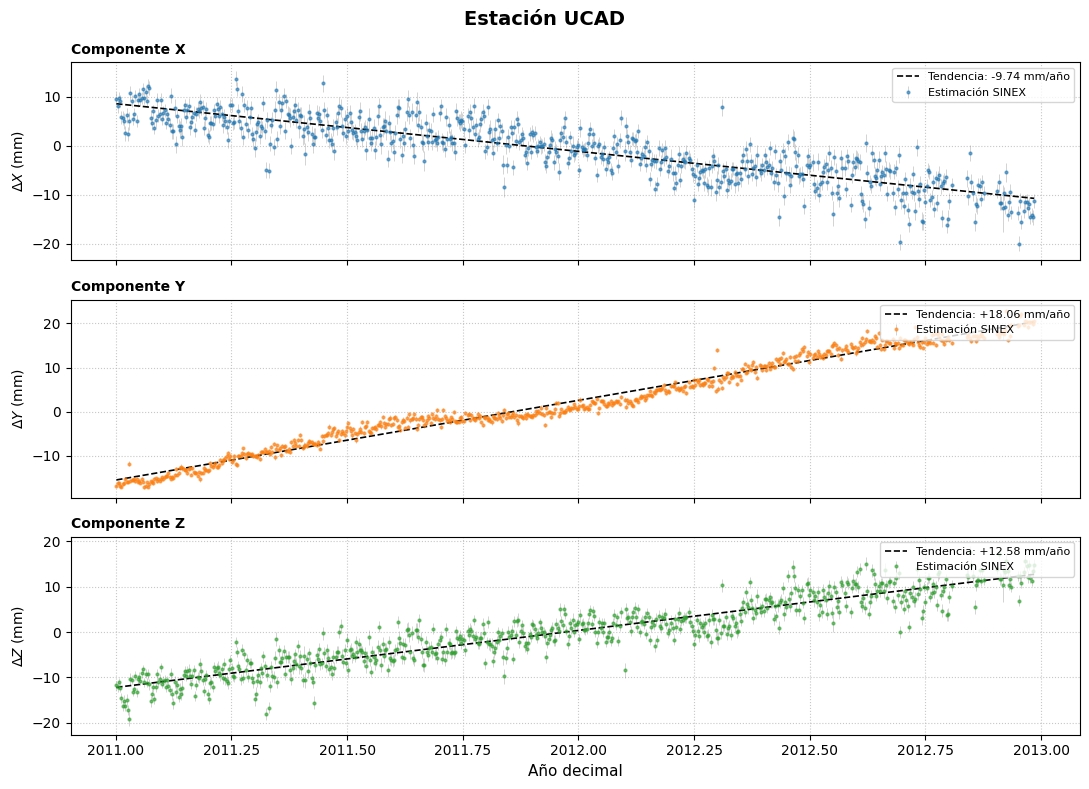

0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativas a VILL

Opción elegida: Graficar coordenadas topocéntricas

Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.
 Estaciones disponibles:

ABAN, ALAC, ALCA, ALCO, ALGC
ALME, ALMR, ANDU, ARAC, CAAL
CABO, CABR, CARA, CASC, CAZA
CEU1, COBA, CRDB, CRTG, CRVC
GRA1, HUEL, HULV, HUOV, JUMM
JUMR, LAGO, LEBR, LORM, LORR
MALA, MAZA, MELI, MLGA, MORA
MOTR, MULA, MURM, MURR, OSUN
PALC, POZO, RABT, ROND, SALI
SEVI, SFER, TARI, TORR, UCAD
UJAE, VIAR, VILL


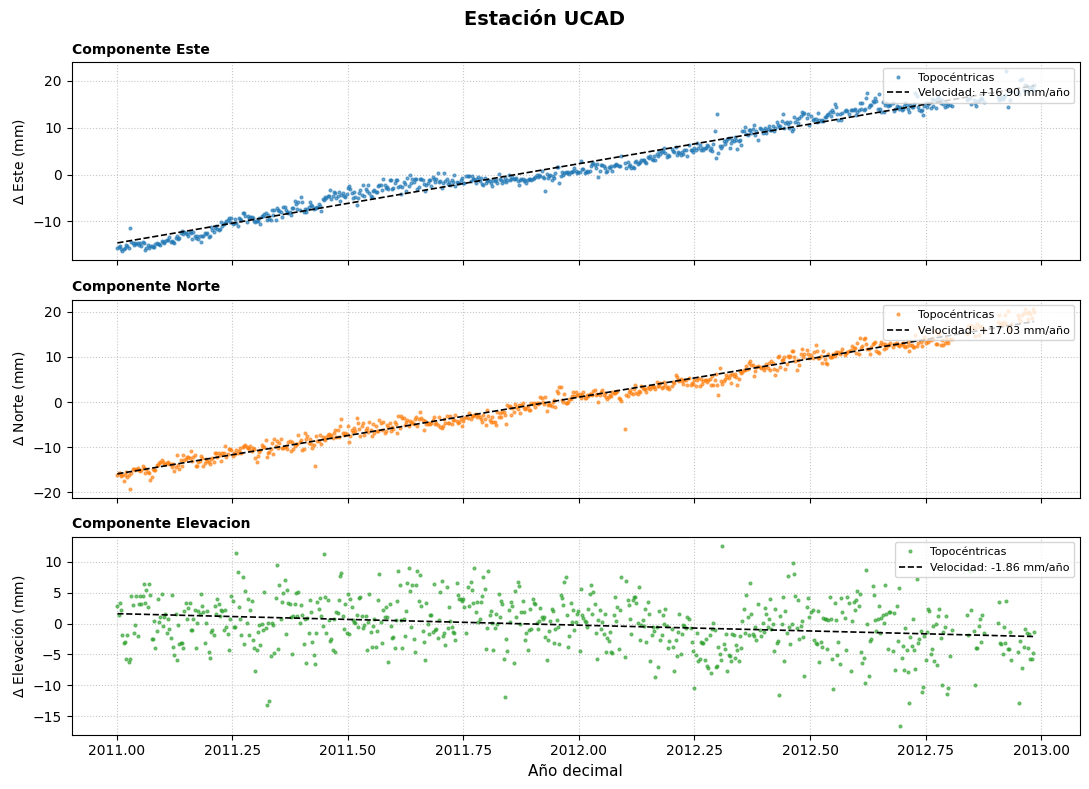

0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativas a VILL

Opción elegida: Suavizar series temporales con wavelets

Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.
 Estaciones disponibles:

ABAN, ALAC, ALCA, ALCO, ALGC
ALME, ALMR, ANDU, ARAC, CAAL
CABO, CABR, CARA, CASC, CAZA
CEU1, COBA, CRDB, CRTG, CRVC
GRA1, HUEL, HULV, HUOV, JUMM
JUMR, LAGO, LEBR, LORM, LORR
MALA, MAZA, MELI, MLGA, MORA
MOTR, MULA, MURM, MURR, OSUN
PALC, POZO, RABT, ROND, SALI
SEVI, SFER, TARI, TORR, UCAD
UJAE, VIAR, VILL


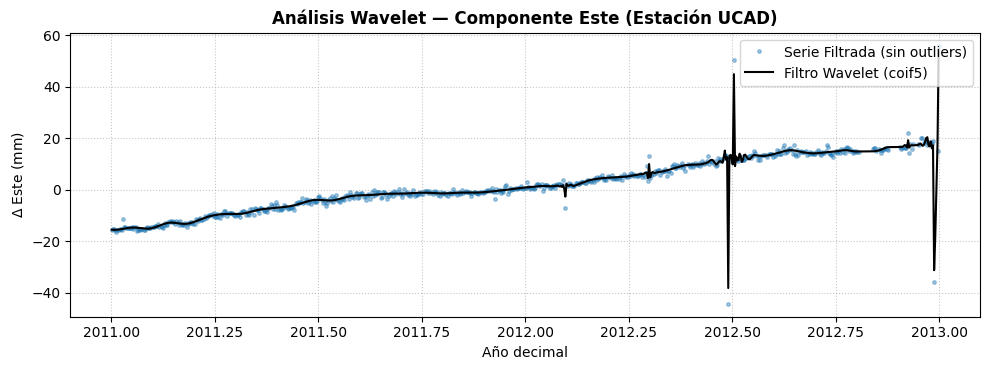

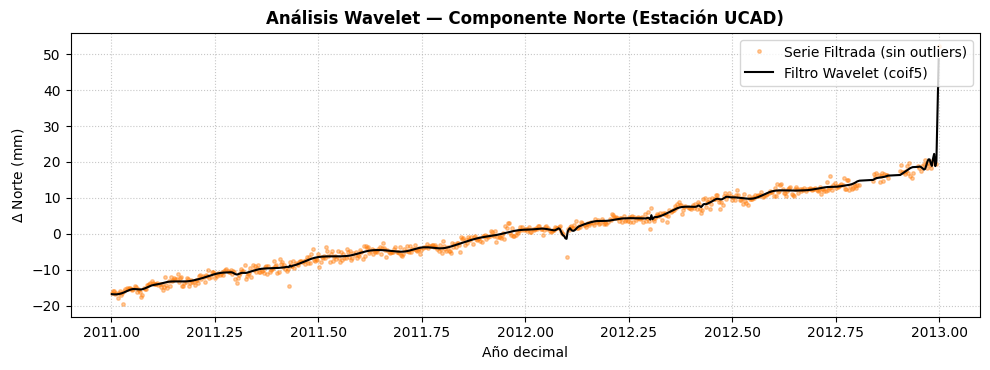

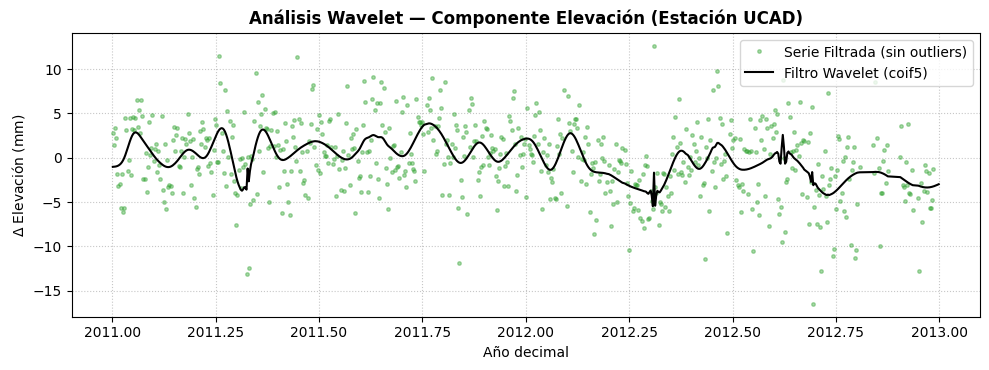

0.-Salir
1.-Crear base de datos
2.-Importar archivos SINEX a SQLite
3.-Consultar estimaciones de una estación
4.-Calcular coordenadas topocéntricas
5.-Exportar coordenadas topocéntricas a Excel
6.-Graficar coordenadas ECEF
7.-Graficar coordenadas topocéntricas
8.-Suavizar series temporales con wavelets
9.-Calcular velocidades topocéntricas
10.-Consultar velocidades calculadas
11.-Consultar velocidades relativas a VILL

Opción elegida: Calcular velocidades topocéntricas

Velocidades calculadas: 53 estaciones.
NOMBRE_ESTACION   LATITUD    LONGITUD  VELOCIDAD_ESTE  VELOCIDAD_NORTE  VELOCIDAD_ALTURA
           ABAN 38.175064   -1.053673    2.562013e+01     1.497368e+01     -1.115515e+01
           ALAC 38.338921   -0.481228    2.476828e+01     1.447244e+01     -1.064499e+01
           ALCA 37.730769   -0.860798    2.504527e+01     1.471699e+01     -1.081755e+01
           ALCO 38.697988   -0.473543    2.412353e+01     1.465201e+01     -1.088466e+01
           ALGC 36.111045   -5.444173    

In [56]:
def main():
    print("\n╔════════════════════════════════════════════╗")
    print("║         ANÁLISIS DE DATOS SINEX            ║")
    print("╚════════════════════════════════════════════╝")
    opciones = [
        'Salir',
        'Crear base de datos',
        'Importar archivos SINEX a SQLite',
        'Consultar estimaciones de una estación',
        'Calcular coordenadas topocéntricas',
        'Exportar coordenadas topocéntricas a Excel',
        'Graficar coordenadas ECEF',
        'Graficar coordenadas topocéntricas',
        'Suavizar series temporales con wavelets',
        'Calcular velocidades topocéntricas',
        'Consultar velocidades calculadas',
        'Consultar velocidades relativas a VILL'
    ]
    while True:
        k = PintarMenu(opciones)
        print(f"\nOpción elegida: {opciones[k]}\n")
        try:
            match k:
                case 0:
                    print('Saliendo del programa.')
                    break
                case 1:
                    CrearBase()
                case 2:
                    LeerArchivosSINEX()
                case 3:
                    print('Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.\n Estaciones disponibles:\n')
                    ListadoEstaciones()
                    nombre = input('Código de la estación: ').strip().upper()
                    df = ObtenerEstacion(nombre)
                    if not df.empty:
                        print(df.to_string(index=False))
                case 4:
                    CalcularCoordenadasTopocentricas()
                case 5:
                    ExportarCoordenadasTopocentricas()
                case 6:
                    print('Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.\n Estaciones disponibles:\n')
                    ListadoEstaciones()
                    nombre = input('Código de la estación: ').strip().upper()
                    graficar_ecef(nombre, f'Estación {nombre}')
                case 7:
                    print('Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.\n Estaciones disponibles:\n')
                    ListadoEstaciones()
                    nombre = input('Código de la estación: ').strip().upper()
                    graficar_topocentricas(nombre, f'Estación {nombre}')
                case 8:
                    print('Introduce el código de una de las estaciones disponibles para consultar sus estimaciones.\n Estaciones disponibles:\n')
                    ListadoEstaciones()
                    nombre = input('Código de la estación: ').strip().upper()
                    procesar_y_graficar_wavelet(nombre, nombre)
                case 9:
                    df = CalcularVelocidadesTopocentricas()
                    if df is not None and not df.empty:
                        print(df.to_string(index=False))
                case 10:
                    df = ObtenerVelocidades()
                    if not df.empty:
                        print(df.to_string(index=False))
                case 11:
                    df = ObtenerVelocidades(relativas=True)
                    if not df.empty:
                        print(df.to_string(index=False))
        except (ValueError, sqlite3.Error, FileNotFoundError, KeyError, IndexError) as error:
            print(f'Error: {error}')
        if k != 0:
            input('\nPulsa Intro para continuar...')


if __name__ == '__main__':
    main()